In [1]:
import os, re, sys, json, shutil, cv2
import pandas as pd
import torch

sys.path.append('../..')
sys.path.append('../../Model')    # O Blocks.index CARREGA A REDE PELO Network/ DE Model/
from Blocks.index import BlockPredictor, BlockSection, FaultStickExtractor, TileGrid, getBlockInfo, getSeismic, modelSummary, saveReport

cv2.setNumThreads(1)              # O DATALOADER CRIA WORKERS POR FORK DEPOIS DO CV2: SEM ISSO OS FILHOS TRAVAM
pd.set_option('display.max_columns', None)

In [ ]:
{'torch': torch.__version__, 'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}

# CONFIGURAÇÃO
- O F3 (Mar do Norte, Holanda) chega como o Iracema: tiles de 128³ com 32 voxels de borda, float32 em `[0, 1]` (p01/p99 do bloco), eixos `(inline, z, xline)`, sem interpretação; o bloco é 651 × 462 × 951 em 11 × 8 × 15 = 1320 tiles
- `BASE_PATH` é a pasta dos modelos (`model_N/` com `info.json` e `model.pth`); `MODELS = []` pega todos os `model_N` dela
- `FULL_PREDICT = False` prediz só os 8 × 15 = 120 tiles cujo núcleo cobre a `INLINE`; `True` prediz o bloco inteiro (1320 tiles, ~5 min por modelo na RTX 5070), o que só se aproveita com `SAVE_TILES` ou `SAVE_PRED`
- `SAVE_TILES = True` grava a máscara de cada tile em `masks/`, na mesma grade e no mesmo shape dos tiles de entrada (~1 GB na inline, ~11 GB no bloco inteiro); `False` não grava nada por tile
- `SAVE_PRED = True` grava o `predicted.npy` do bloco (651 × 462 × 951, ~1,1 GB, pede `FULL_PREDICT`)
- `SKIP_DONE = True` reaproveita o que já está em disco: um `predicted.npy` pronto dispensa a predição, e sem ele os tiles com `.dat` inteiro em `masks/` são lidos em vez de preditos
- `OVERLAP` e `WINDOW` controlam a janela deslizante; `WINDOW = None` usa a janela em que a rede foi treinada
- `STICK_TOL`, `STICK_MIN` e `STICK_GAP` são os botões do extrator, os mesmos calibrados no Marlim (mergulho aceito de 43° a 76°)

In [3]:
BLOCK      = 'F3'
BASE_PATH  = '../../Documents/Backups/Dissertacao/'    # PASTA DOS MODELOS: '../../Model/Backup', '../../Documents/Backups/Marcia', ...
TILES_DIR  = 'files/patches'                           # O BLOCO INTEIRO, UM .DAT POR TILE
META_PATH  = 'files/patch_metadata.json'
CACHE_DIR  = 'files/cache'
OUTPUT_DIR = f'{BASE_PATH}/outputs/{BLOCK.lower()}'    # FIGURAS E TABELA DE TODOS OS MODELOS SELECIONADOS

MODELS          = ['model_5']   # [] = TODOS OS MODELOS DE BASE_PATH
INLINE          = 325           # INLINE DAS FIGURAS (0 A 650)
FULL_PREDICT    = True          # False PREDIZ SÓ OS TILES QUE COBREM A INLINE; True O BLOCO INTEIRO
SAVE_TILES      = False         # True GRAVA A MÁSCARA DE CADA TILE EM masks/ (UM .DAT DE ~8 MB POR TILE)
SAVE_PRED       = False         # True GRAVA O predicted.npy DO BLOCO INTEIRO (~1,1 GB, PEDE FULL_PREDICT)
SKIP_DONE       = True          # True REAPROVEITA O QUE JÁ ESTÁ EM DISCO (predicted.npy OU masks/)
OVERLAP         = 0.25          # SOBREPOSIÇÃO ENTRE JANELAS (0 = CORTE SECO, DO JEITO QUE O FORMAT CORTA O TREINO)
WINDOW          = None          # None = A JANELA DO TREINO (info.json); FORCE UMA TUPLA PARA TESTAR OUTRA, EX: (64, 64, 64)
MODEL_THRESHOLD = 0.5           # PROBABILIDADE A PARTIR DA QUAL O VOXEL ENTRA NA MÁSCARA

STICK_TOL = 0.80    # PERMISSIVIDADE DO EXTRATOR: 0 SÓ O TRAÇO ÓBVIO, 1 TUDO QUE PARECER FALHA
STICK_MIN = 140     # PX
STICK_GAP = 59      # PX: MAIOR LACUNA COSTURADA DENTRO DE UM STICK

models = MODELS or sorted((m for m in os.listdir(BASE_PATH) if re.fullmatch(r'model_\d+', m)), key=lambda n: int(n.split('_')[-1]))
models

['model_5']

# BLOCO
- `TileGrid` lê o `patch_metadata.json` e sabe onde o núcleo de cada tile (o tile sem os 32 voxels de borda) cai no volume, no mesmo corte em que os tiles foram gerados; o volume é montado pelos núcleos, com o shape do metadata, e um tile faltando levanta erro em vez de deixar buraco zerado
- `getBlockInfo` resume o bloco: shape inteiro, tamanho do tile, grade, total de tiles, quantos faltam em disco e o mínimo, máximo, média e desvio dos valores numa amostra de 100 tiles espalhados pela grade
- Tile normalizado (min-max ou p01/p99) fica em $[0, 1]$; padronizado fica com média 0 e desvio 1

In [4]:
grid = TileGrid(META_PATH)
getBlockInfo(grid, TILES_DIR)

,pasta,shape,tile,grade,tiles,faltando,amostra,min,max,media,desvio
0,files/patches,"(651, 462, 951)","(128, 128, 128)","(11, 8, 15)",1320,0,100,0.0,1.0,0.50215,0.17844


# MODELOS
- Rede, janela de treino, dataset e IoU de teste de cada modelo, lidos do `info.json`; o `rotulo` vai na legenda das figuras

In [5]:
pd.DataFrame([modelSummary(BASE_PATH, name) for name in models])

,nome,rede,janela,dataset,iou_teste,rotulo
0,model_5,dbrnet,128×128×128,dataset_74_wu,0.7568,model_5 · dbrnet 128×128×128 (iou=0.757)


# PREDIÇÃO
- `BlockPredictor` cuida de um modelo: carrega os pesos só quando algum tile está pendente, e só se o `scaling` do treino for `'normalize'` ou `'percentile'` (o bloco está em `[0, 1]`)
- Cada tile passa pela `SlidingWindow` na janela do treino: as janelas se somam com peso de Hanning (~1 no centro, ~0 na borda) para a emenda não virar degrau, e o tile menor que a janela é espelhado
- O núcleo de cada tile predito vai direto para a inline das figuras e, com `SAVE_PRED`, para o `predicted.npy`; a tabela abaixo é quantos tiles a rodada cobre e quantos ainda faltam predizer

In [6]:
options    = {'overlap': OVERLAP, 'window': WINDOW, 'skipDone': SKIP_DONE, 'saveTiles': SAVE_TILES, 'savePred': SAVE_PRED}
predictors = {name: BlockPredictor(f'{BASE_PATH}/{name}', **options) for name in models}
region     = None if FULL_PREDICT else INLINE    # None = O BLOCO INTEIRO
pd.DataFrame([{'modelo': name, 'tiles': len(grid.names(region)), 'pendentes': len(predictors[name].pending(grid, f'{BASE_PATH}/{name}/{BLOCK.lower()}', region))} for name in models])

,modelo,tiles,pendentes
0,model_5,1320,1288


# EXTRAÇÃO DE STICKS
- Cada falha de uma seção 2D vira uma reta (**stick**), a mesma representação para a rede e para o especialista
- **Evidência**: a probabilidade suavizada e reescalada para $[0,1]$; o piso sobe pelo percentil quando a predição é densa, para a teia não explodir o traçado
- **Votação tipo Hough**: a evidência somada numa janela reta de `seedLen` px em cada orientação plausível; os picos são as sementes
- **Traçado**: a semente se estende enquanto houver suporte, tolerando lacunas de até `STICK_GAP` px, e a reta é reajustada ao centro de massa da evidência por **PCA**
- **Filtros**: mergulho entre 43° e 76°, comprimento mínimo `STICK_MIN`, preenchimento, **energia sísmica** (a falha precisa cortar refletores, não a água nem a zona morta) e **ângulo com as camadas** pelo tensor de estrutura
- **Matching pursuit**: aceita a melhor reta, consome o corredor dela e segue para a próxima; no fim, retas colineares se fundem e as que correm por cima de uma maior saem

In [7]:
extractor = FaultStickExtractor(STICK_TOL, STICK_MIN, STICK_GAP)
pd.Series({'tolerance': extractor.tolerance, 'minLen': extractor.minLen, 'maxGap': extractor.maxGap, 'dipMin': extractor.dipMin, 'dipMax': extractor.dipMax})

tolerance      0.8
minLen       140.0
maxGap        59.0
dipMin        43.0
dipMax        76.0
dtype: float64

# SEÇÃO DO BLOCO
- `BlockSection` faz o papel do `FaultComparer` do Marlim: recebe a inline predita, extrai os sticks e desenha os painéis; o F3 não tem anotação, então não há métrica contra o especialista
- A sísmica da `INLINE` sai só dos tiles que a cobrem (8 × 15 tiles), sem montar o bloco inteiro, e fica em `files/cache/real_inline_<inline>.npy`

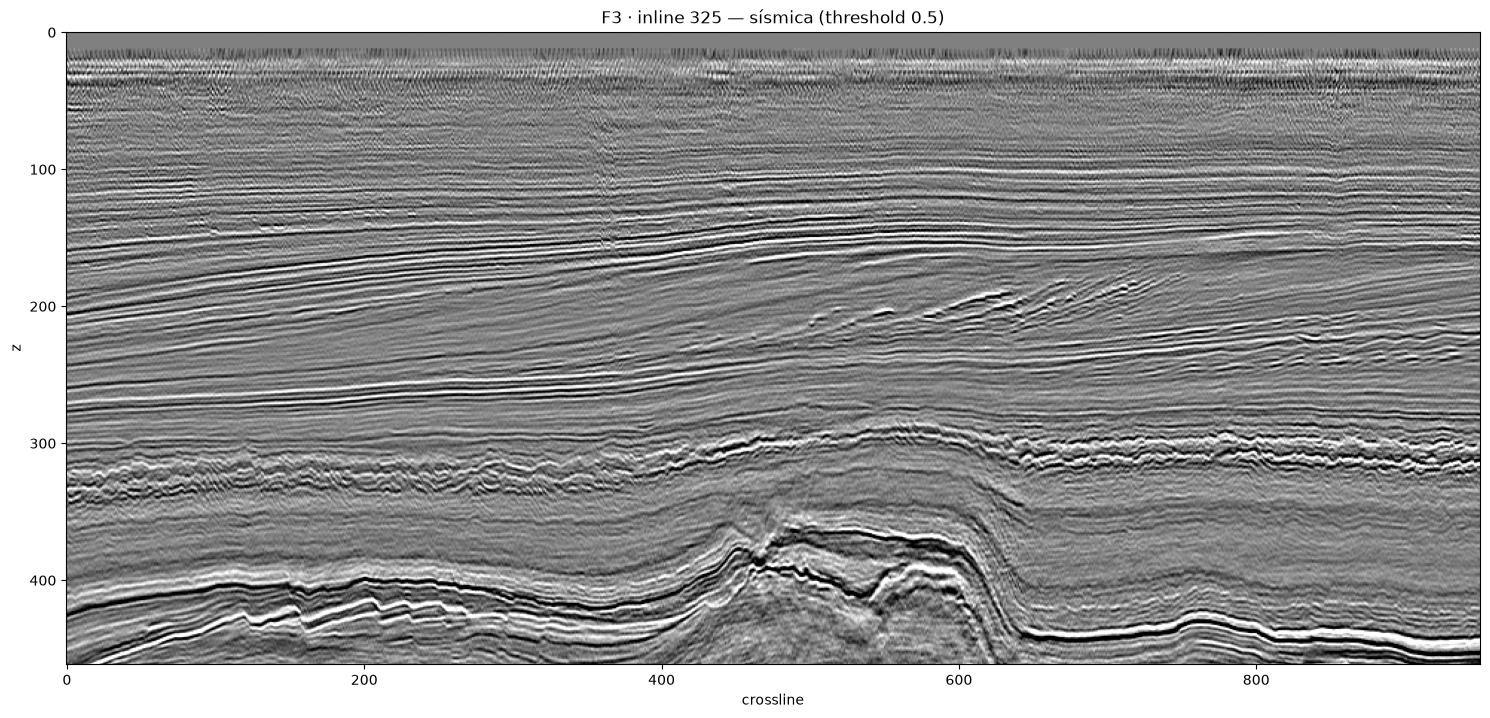

In [8]:
seismic = getSeismic(grid, TILES_DIR, f'{CACHE_DIR}/real_inline_{INLINE}.npy', INLINE)
section = BlockSection(seismic, extractor, MODEL_THRESHOLD)
section.show('seismic', title=f'{BLOCK} · inline {INLINE}')

# PREDIÇÃO E FIGURAS POR MODELO
- Para cada modelo: prediz os tiles pendentes, extrai os sticks da inline e grava as três figuras na pasta `f3/` do modelo (`predicted_seismic_<inline>`, `predicted_mask_<inline>`, `predicted_sticks_<inline>`), copiadas para `OUTPUT_DIR` com o modelo e a rede no nome
- O `predicted.npy` é montado direto em disco por memmap e só ganha o nome final quando fica completo, então um arquivo interrompido nunca passa por pronto
- Um modelo sem `model.pth`, ou com `scaling` fora de `[0, 1]`, fica fora da tabela; a rede é solta antes do próximo modelo

In [ ]:
# PREDIZ O BLOCO COM UM MODELO, SALVA AS TRÊS FIGURAS DA INLINE (NA PASTA DO MODELO E EM OUTPUT_DIR) E DEVOLVE A LINHA DA TABELA
def predictedBlock(name):
    model    = modelSummary(BASE_PATH, name)
    blockDir = f'{BASE_PATH}/{name}/{BLOCK.lower()}'
    values   = predictors[name].predict(grid, TILES_DIR, blockDir, INLINE, FULL_PREDICT)

    if values is None:
        return None

    section = BlockSection(seismic, extractor, MODEL_THRESHOLD)
    section.setSection(model['rotulo'], values, 'red')

    metrics = section.metrics(model['rotulo'])
    title   = f"{BLOCK} (Inline {INLINE}) | Dataset: {str(model['dataset']).upper()} | Modelo: {name} ({model['rede']})"
    titles  = {'seismic': title, 'mask': title, 'sticks': f"{title} | Sticks: {metrics['sticks']}"}

    for kind, text in titles.items():
        section.show(kind, title=text, save=f'{blockDir}/predicted_{kind}_{INLINE}.png')
        shutil.copy(f'{blockDir}/predicted_{kind}_{INLINE}.png', f'{OUTPUT_DIR}/{name}_{model["rede"]}_inline_{INLINE}_{kind}.png')

    run = json.load(open(f'{blockDir}/predict.json')) if os.path.exists(f'{blockDir}/predict.json') else {}
    return {'modelo': name, **{key: model[key] for key in ('rede', 'janela', 'iou_teste')}, 'overlap': run.get('overlap'), 'inline': INLINE, **metrics}


os.makedirs(OUTPUT_DIR, exist_ok=True)
rows = []

for name in models:
    rows.append(predictedBlock(name))
    predictors[name].reset()

rows = [row for row in rows if row]
pd.DataFrame(rows)

# TABELA NA RAIZ
- `sticks_report.csv` fica em `OUTPUT_DIR` e junta as linhas novas às do CSV anterior: um par (modelo, inline) recalculado substitui o antigo, e rede, janela e IoU de teste são relidos do `info.json`

In [ ]:
saveReport(rows, f'{OUTPUT_DIR}/sticks_report.csv', BASE_PATH, 'inline', 'sticks')